In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv(r"D:\my projects\superstore-sales-analysis\data\superstore_sales.csv")

# Display the first five rows
display(df.head())


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [3]:

# Remove completely empty rows
df = df.dropna(how="all").copy()

# Convert sales and profit to numeric values
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df["Profit"] = pd.to_numeric(df["Profit"], errors="coerce")

# Parse order dates
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

# Remove records missing essential analysis fields
df = df.dropna(
    subset=["Order Date", "Sales", "Profit"]
).copy()

# Extract year and month
df["Year-Month"] = (
    df["Order Date"].dt.to_period("M")
)

# Convert Year-Month to a timestamp for plotting
df["Month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()

print("Clean dataset shape:", df.shape)
print("Remaining missing values:")
print(df.isnull().sum())


Clean dataset shape: (9994, 23)
Remaining missing values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
Year-Month        0
Month             0
dtype: int64


In [4]:

# Sales and profit by product category
category_summary = (
    df.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(category_summary)

# Sales and profit by region
region_summary = (
    df.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(region_summary)

# Sales and profit by customer segment
segment_summary = (
    df.groupby("Segment")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(segment_summary)


,Total_Sales,Total_Profit
Category,,
Technology,836154.0330,145454.9481
Furniture,741999.7953,18451.2728
Office Supplies,719047.0320,122490.8008


,Total_Sales,Total_Profit
Region,,
West,725457.8245,108418.4489
East,678781.2400,91522.7800
Central,501239.8908,39706.3625
South,391721.9050,46749.4303


,Total_Sales,Total_Profit
Segment,,
Consumer,1.161401e+06,134119.2092
Corporate,7.061464e+05,91979.1340
Home Office,4.296531e+05,60298.6785


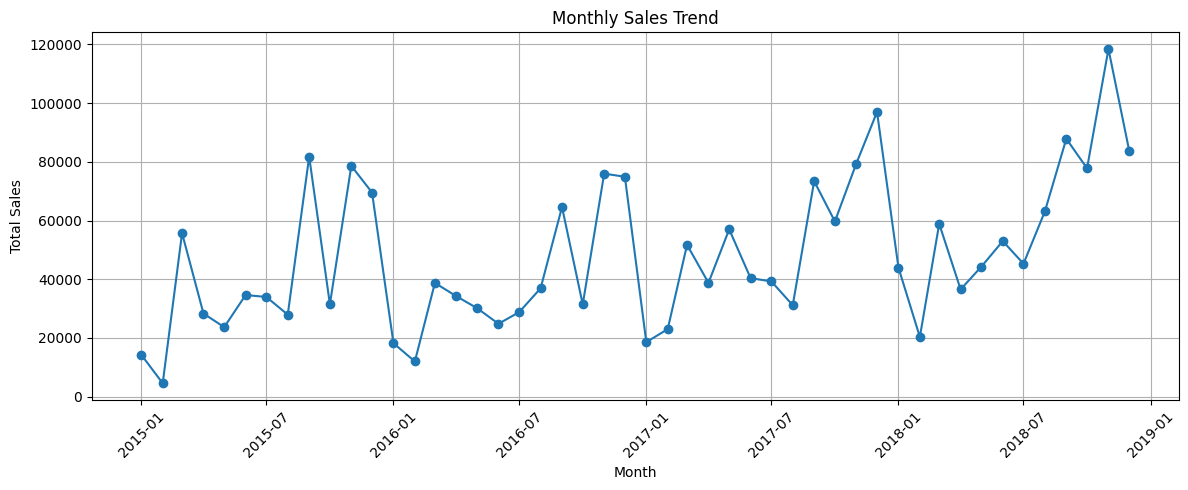

In [5]:

monthly_sales = (
    df.groupby("Month")["Sales"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()



# Business Observations

## 1. Product Category
The category with the highest sales is [category].
Its total sales are [value], while total profit is [value].

## 2. Regional Performance
The region with the highest sales is [region].
This indicates [business implication].

## 3. Customer Segment
The customer segment generating the highest profit is [segment].
This suggests [business implication].

## 4. Monthly Sales Trend
The highest-sales month is [month].
The lowest-sales month is [month].
This may indicate [seasonal pattern].

## 5. Discount and Profit
The scatter plot shows [observed relationship].
A possible business recommendation is [recommendation].

